# Exercise project 1


### <i>Dataset evaluation report </i>

<i>Student name</i>

---

### Summary

|Topic               |Description               |
|--------------------|--------------------------|
|Dataset Name:       |    Heart Failure Prediction Dataset                      |
|Dataset Link:       |    https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction                      | 
|Target Variable:    |            HeartDisease              | 
|Type of Dataset:    | Classification|

<br>



---


## Overview

<br>
<br>

##### <b> <u>Step 1a</u>: Inspect the datatypes for each column </b> 

<i>
<strong style='color:orange ; background-color:black;'>Fix these before continuing below.</strong>


Some visuals require numeric/datetime columns (heatmaps, matrices, etc). Most common problem is date-columns being in string/object -format => change to DateTime -objects.
</i>

<i>Easiest option is probably to use pandas' dtypes-feature.</i>

All seems good here, no need to process data types!

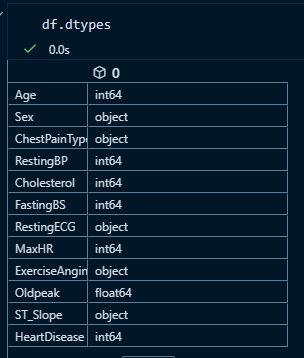
<br><br>
<br>

##### <b> <u>Step 1b</u>: Inspect the shape of the dataset (the number of rows and columns.) </b> 

<i>


How many rows and columns are in your dataset? 

Are you expecting any issues if you were to train a model with this amount of rows/columns?

Justify your answer. Provide visuals if needed.

<br>

<u><b>Hint:</b></u> ydata-profiling, pandas.shape()

</i>

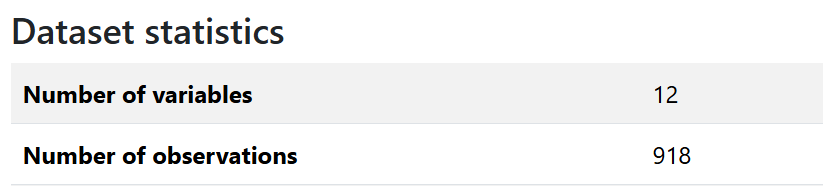

There are only 918 rows (observations) and 12 variables in this data. This is a small dataset, so it can be challenging for ML. We might need synthetic data techniques to increase the amount of data later.
<br><br>
<br>

##### <b> <u>Step 1c</u>: Inspect NaN values, duplicates, zeroes, invalid/nonsensical/problematic values </b> 

<i>
How many missing values are there? 
<br>

How many duplicate values are there? 

Are there any abnormal amounts of zeroes?

Are there any values which don't make sense or don't belong there?

Please explain how each of these values in your dataset might or might not be problematic.

<br>
</i>

<u><b>Hint:</b></u> ydata-profiling, pandas

0 Missing values and 0 duplicate values:
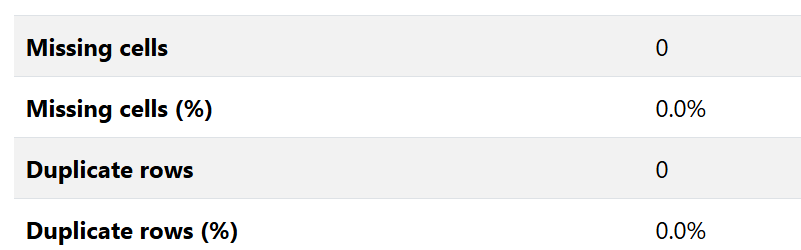

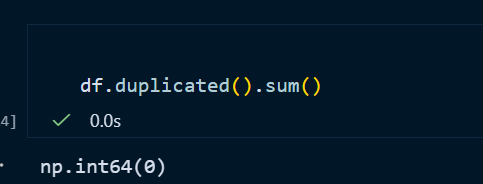

Abnormal zeros:

<ul>
<li> Cholesterol: 172 zeros (18.7%). Abnormal. </li>
<li> RestingBP: 1 zero. An error. </li>
<li> Oldpeak: 368 zeros (40.1%). High, but legitimate. </li>
</ul>

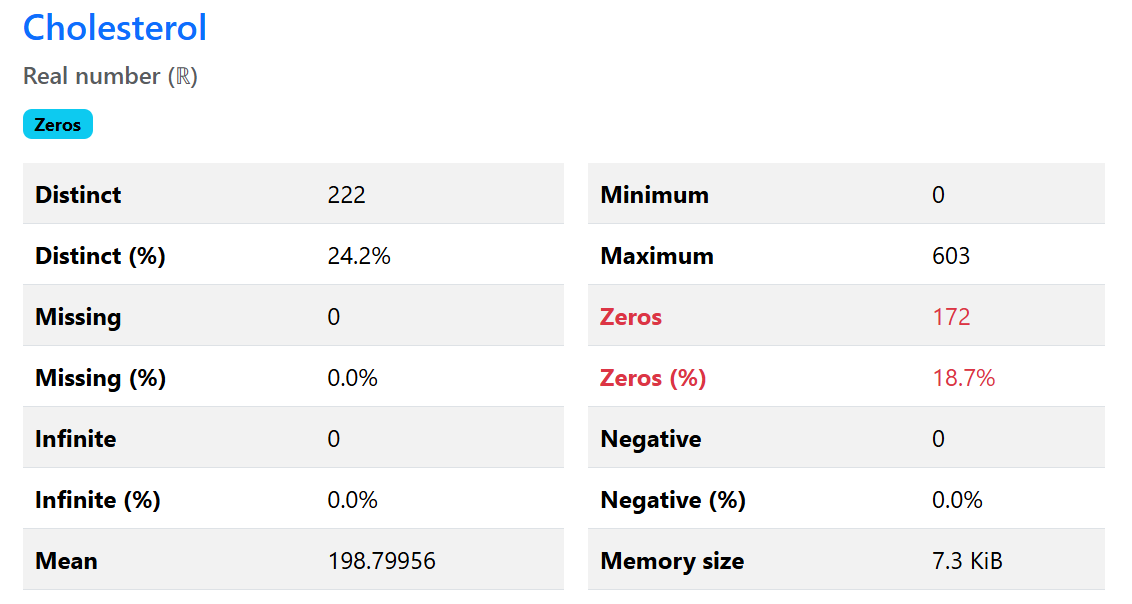

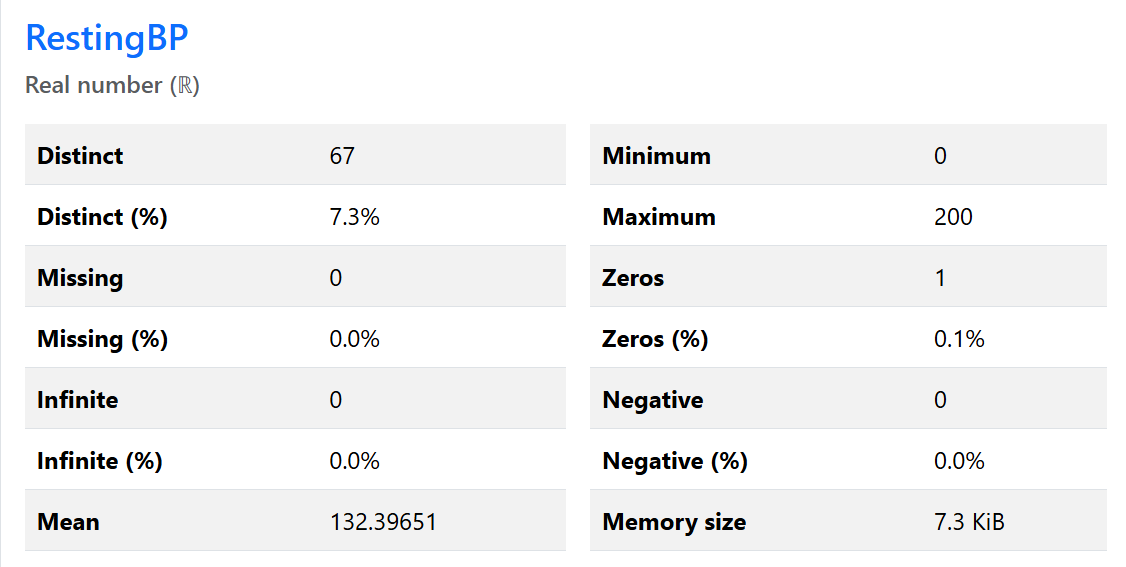

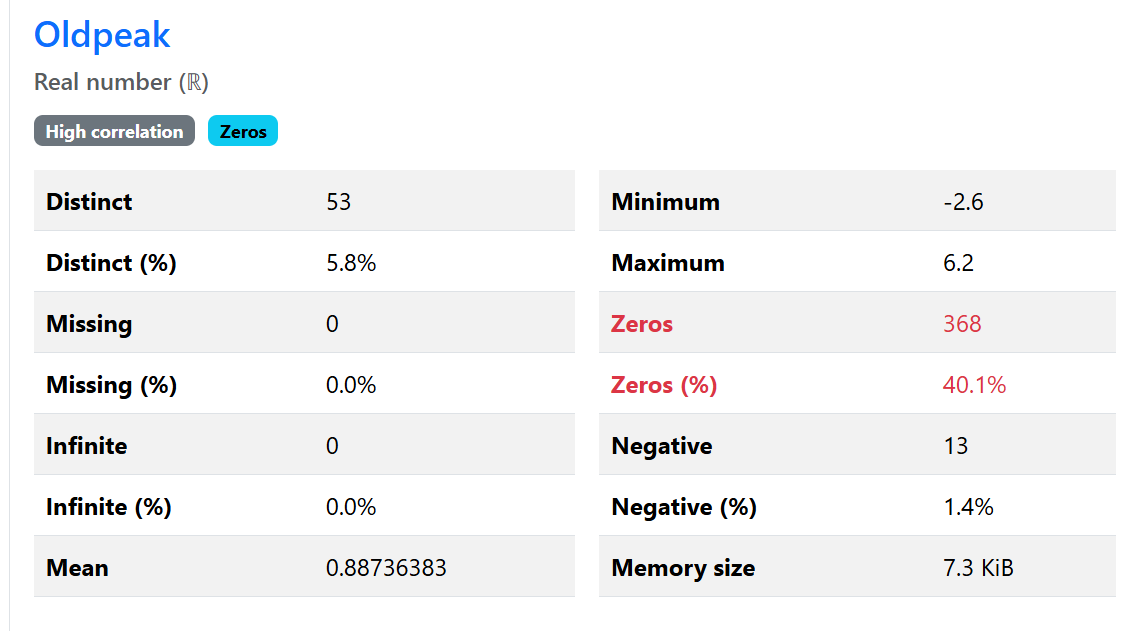

Values that don’t make sense, and why they matter:

<ul>
<li> RestingBP = 0 (1 row): Blood pressure can’t be 0 in a living person, so this is a mistake. It’s only one row, so it’s a small problem. I can delete that row or replace it with the middle (median) value.</li> 

<li> Cholesterol = 0 (172 rows): Cholesterol can’t be 0 either. These zeros mean the test was never recorded, so they are really missing values. This is the biggest problem band this can confuse a model. I can mark them as missing, then fill them with the median or add a “was missing” column.</li> 

<li> Oldpeak = 0 (368 rows): A zero here is real. It means there was no change in the heart’s ST reading, which is normal. It’s not a problem. Most values are just 0, so the data leans to one side. </li> 

</ul>
<br>
<br>

##### <b> <u>Step 1d</u>: Are there any alerts recommendations?</b> 

<i>
When you used a big-picture tool(s), what kind of alerts did it give you? Were they valid concerns?

<br>

Justify. If possible, please show a visual.

<br>

<u><b>Hint:</b></u> ydata-profiling, SweetViz, AutoViz, dataprep etc.
</i>

ydata -alerts:
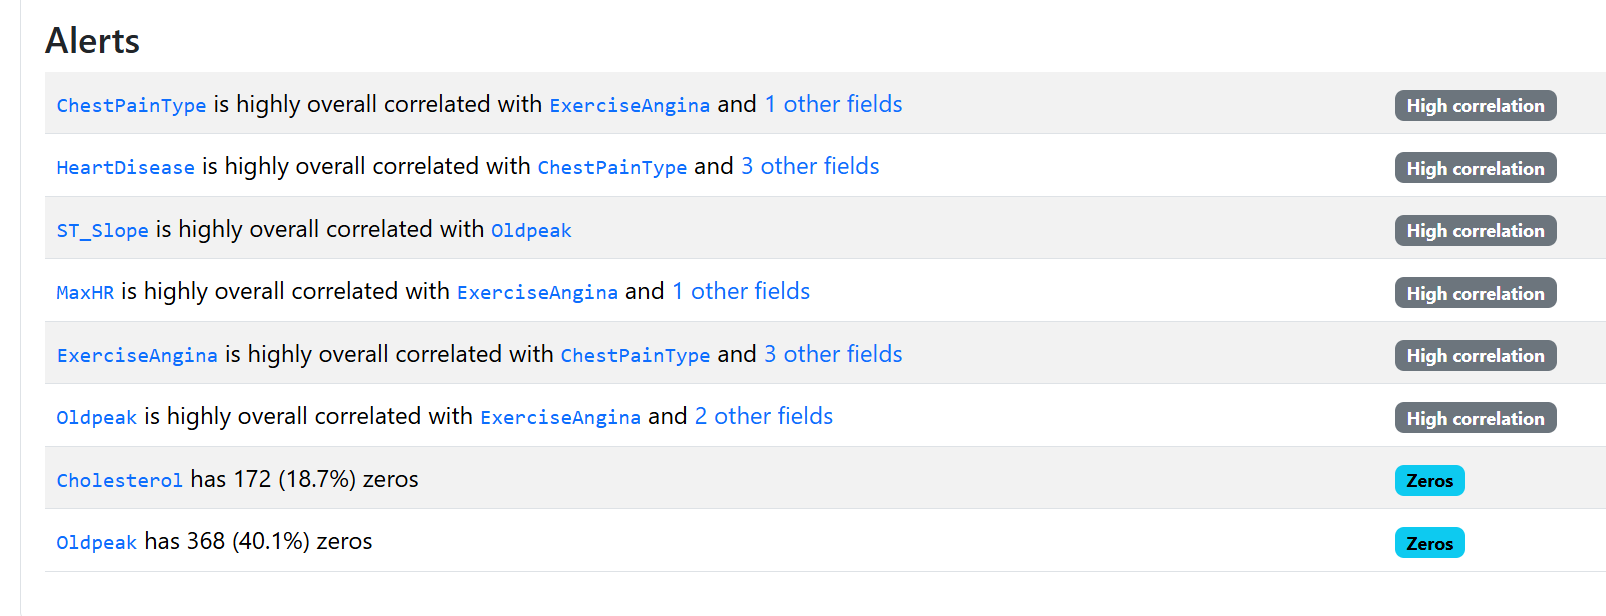


<br>
<br>

---

## Distribution, outliers, imbalances

<br>
<br>

##### <b> <u>Step 2a</u>: Distributions & imbalances</b> 

<i>
Inspect the distribution for the target variable and its features. 
<br>

Which columns may have distributions which are problematic for machine learning? 
<br>

For each problematic column, describe what kind of problems they exhibit (for example: left-skewed, right-skewed, high kurtosis, low kurtosis).

Do you expect this will be an issue when training ML models? Justify your answers. Please introduce visuals.

 <br>

<u>OPTIONAL:</u> 

Q-Q plots. Another way to visualize distributions is using Q-Q plots. 

These are particularly good for identifying thin/thick-tailed distributions and are an alternative to histograms. 

Do these phenomena exist in your dataset?  

<br>

<u><b>Hint:</b></u> ydata, SweetViz, Dtale, pandas…



</i>

<b> HeartDisease (target): </b>

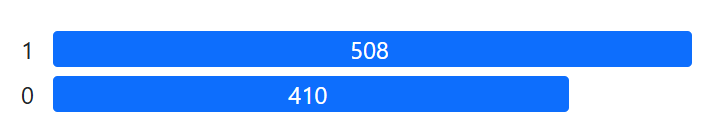

Binary: 508 with heart disease (1) vs 410 without (0), about 55% vs 45%. This is a slight imbalance, close to even.

Problem for ML: Unlikely to be an issue. Use a stratified split and check precision, recall and F1, not just accuracy.

Note for later: The “High correlation” flag is expected for a target. It means other columns (likely Oldpeak, ST_Slope) will be good predictors.

<b> Age </b>

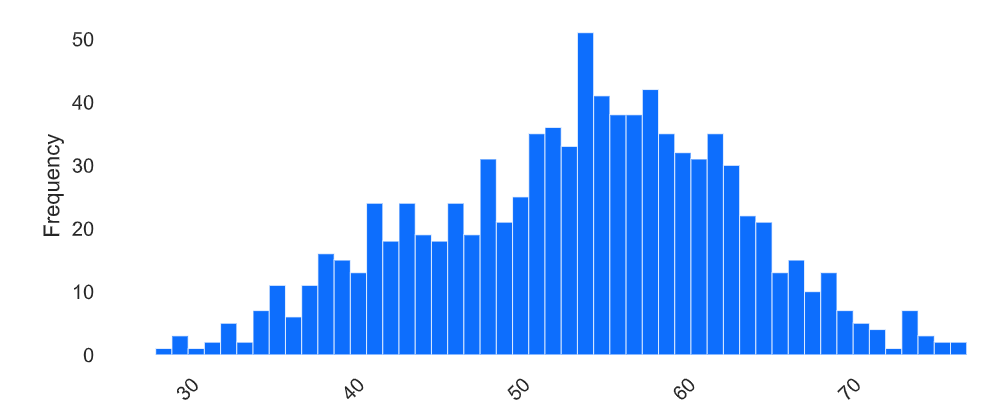

Roughly bell-shaped, slightly left-skewed, with a longer tail toward younger ages and a few small gaps at both ends.This is unlikely to be an issue. The shape is close to normal, with no extreme skew or outliers.

<b> Sex </b>

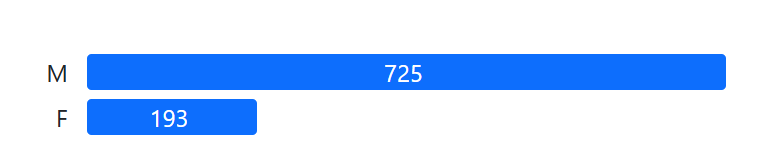

Binary, with a clear imbalance toward males. Males make up the large majority and females only a small minority. This can possibly be an issue. The model sees fewer female examples, so it may learn patterns that fit males better and perform worse on females.

<b> ChestPainType </b>

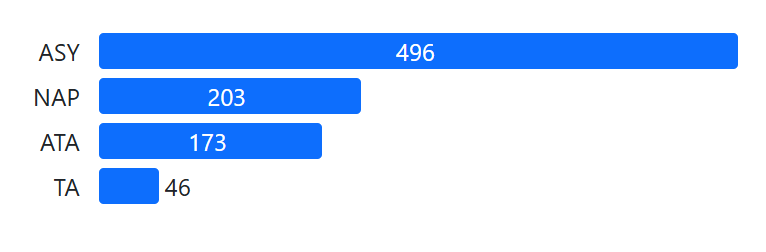

Four categories, clearly imbalanced. ASY dominates, NAP and ATA are mid-sized, and TA is very small. this is possibly an issue. TA has very few examples, so the model has little to learn from for that group and may treat it unreliably. ASY being so large can also dominate what the model learns. 

<b> RestingBP </b>

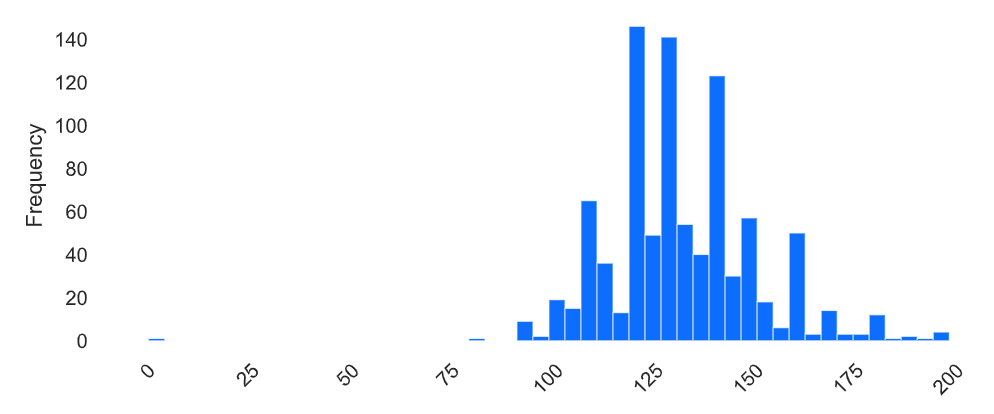

Mostly bell-shaped but right-skewed, with a longer tail toward high blood pressure. The zero is an impossible value and acts as an outlier.

<b> Cholesterol </b>

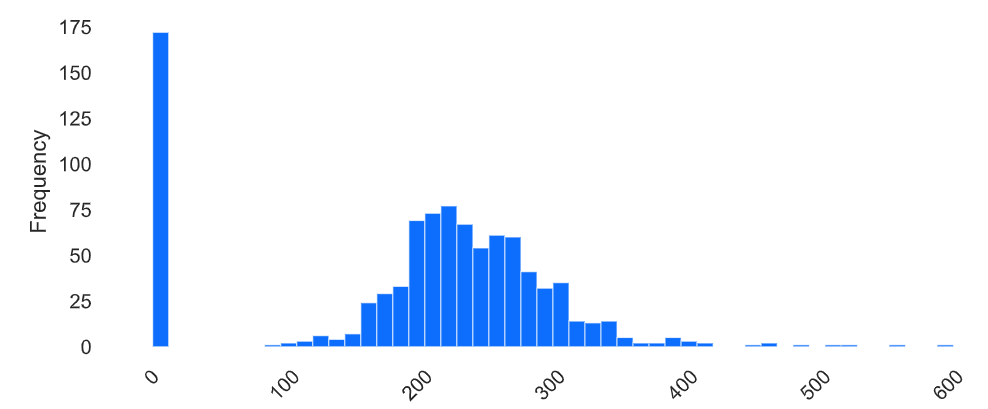

There is a huge spike at 0, and the rest forms a bell shape that is right-skewed. This will be a serious issue. The zeros are not real readings but could be the missing values, so the model might see a false cluster of low cholesterol.

<b> FastingBS </b>

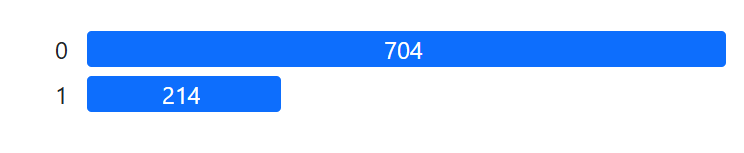

Binary, with a clear imbalance. Most patients are 0 (fasting blood sugar not high) and a smaller group is 1 (high). Class 1 has fewer examples, so the model has less to learn from for that group. 

<b> RestingECG </b>

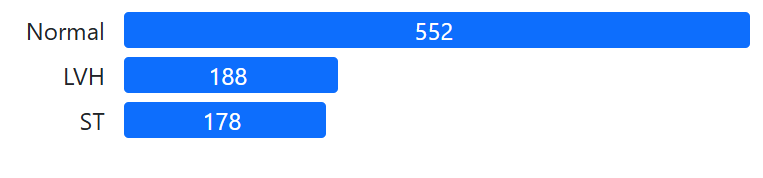

Three categories, with an imbalance. Normal is the large majority, while LVH and ST are much smaller and close in size to each other. The two smaller groups have fewer examples but may be not an issue as each still has data to learn from.


<b> MaxHR </b>

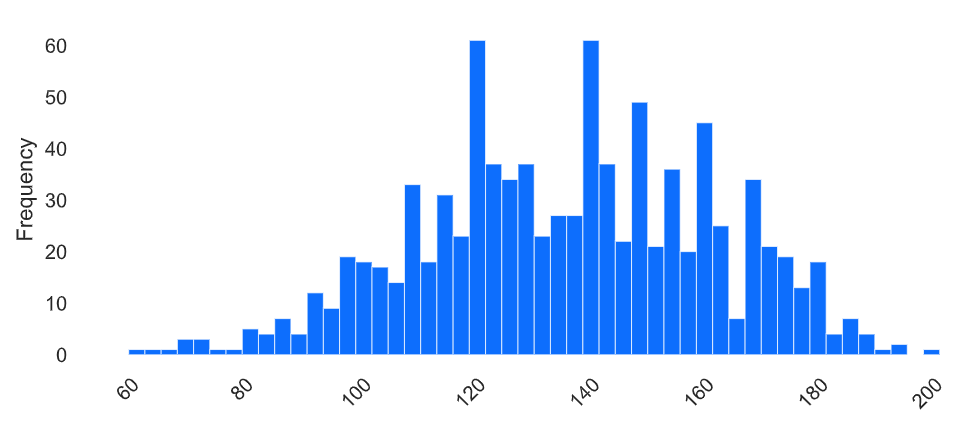

oughly bell-shaped and wide, with a slight left skew. The spread is wide and close to normal,

<b> ExerciseAngina </b>

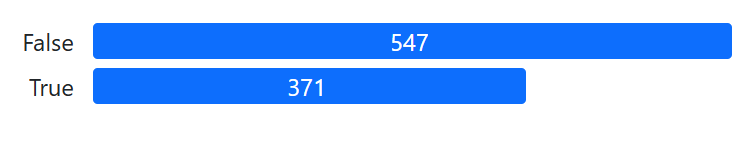

Binary, with a bit of imbalance. Most patients are False (no exercise-induced angina), and a smaller but still large group is True. It is one of the more balanced columns in the dataset.

<b> Oldpeak </b>

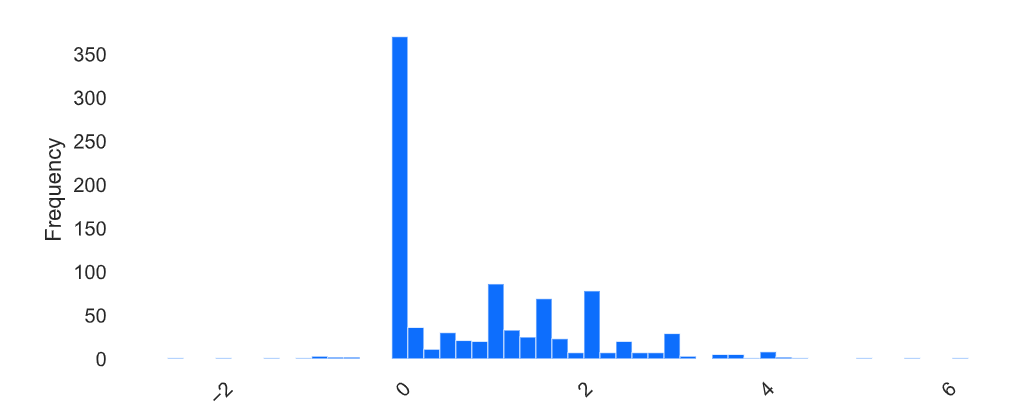

Most values are 0, and a few are much higher, so the data leans heavily to the right.

<br><br>
<br>

##### <b> <u>Step 2b</u>: Multicollinearity & redundancy </b> 

<i>
Some columns may prove to be redundant to others -- Or even worse, they give away the answer entirely.
    <br>

Are there any columns which are redundant and/or suggest high multi-collinearity? 

Which tool(s)/test(s) have you performed to come to this conclusion? 

Justify your answer and, if possible, produce your results as an image below.

<br>

<u><b>Hint:</b></u> VIF test, Correlation Matrix, Phik-matrix, RFE etc.

</i>

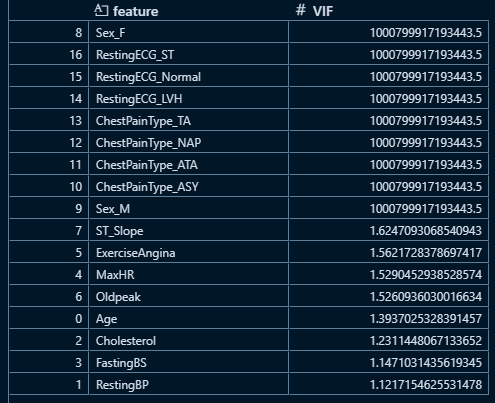

Only the ChestPainType variables show slightly higher VIF values (about 4 to 6), but that is expected, since they were split from the same nominal category (ChestPainType). The same applies to RestingECG, but its values are low.

Other than that, no extremely high VIF values, so no redundancy is implied. Nothing seems to be correlating heavily, so there might not be redundancy here.


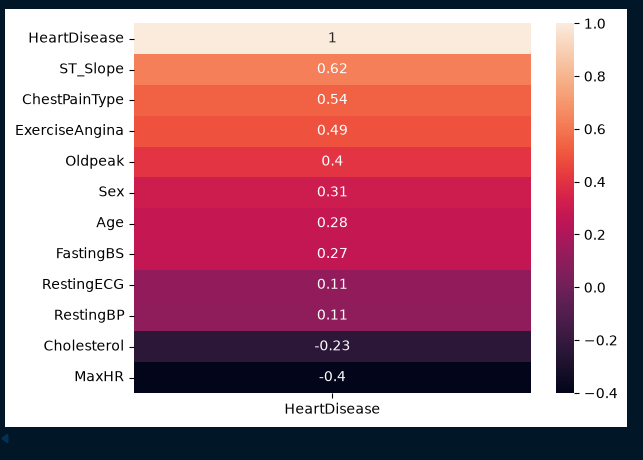

ST_Slope, ChestPainType and ExerciseAngina have the strongest associations with HeartDisease (about 0.5 to 0.6). Oldpeak and MaxHR are moderate (about 0.4, with MaxHR negative). Sex, Age and FastingBS are weaker, while RestingECG and RestingBP have very little association with the target. No feature correlates extremely highly with HeartDisease

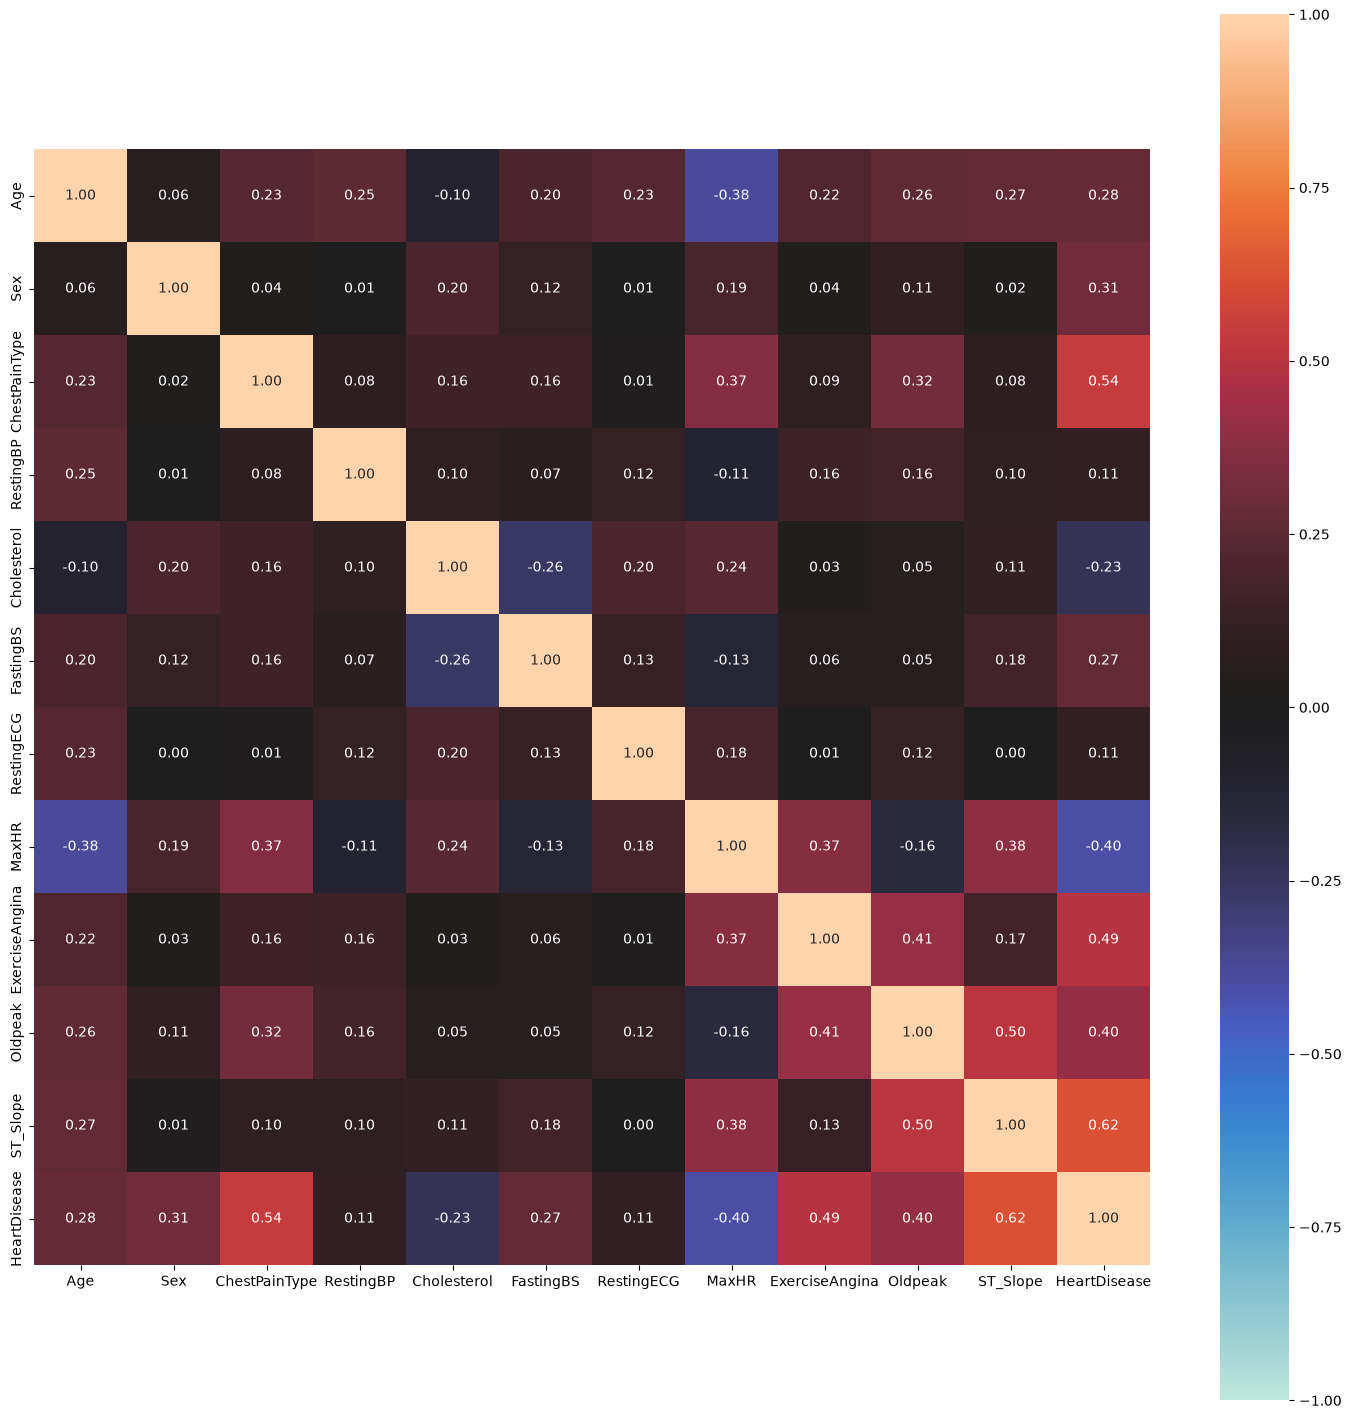

The strongest feature-to-feature association is between Oldpeak and ST_Slope (0.50), followed by Oldpeak and ExerciseAngina (0.41). Age and MaxHR (-0.38) and MaxHR with ST_Slope, ChestPainType and ExerciseAngina (about 0.37 to 0.38) are moderate, and make medical sense.

No pair of features correlates heavily, so there is no clear redundancy. Nothing is close to 1, so no variable duplicates another.
<br>
<br>
<br>

##### <b> <u>Step 2c</u>: High cardinality</b> 

<i>
Inspect each categorical column for high-cardinality (high percentage of unique values in the dataset). 

<br>

Which columns, if any, contain an unusual or problematic amount of unique values?  Which tool(s) or method(s) did you use to come to this conclusion? 

Justify your answer and, if possible, produce the output as a visual.

<br>

<u><b>Hint:</b></u> Big picture tool like ydata-profiling, pd.value_counts()

</i>

None of the categorical columns has high cardinality. Every one has only 2 to 4 categories, which is under 0.5% of the 918 rows. High cardinality would be something like an ID or name column, where almost every value is unique (close to 100%).

Sex:

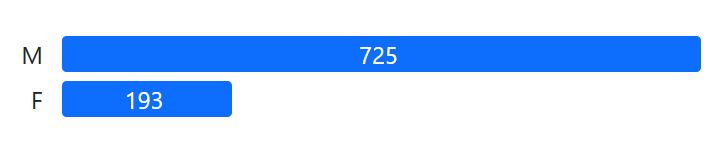

ChestPainType:

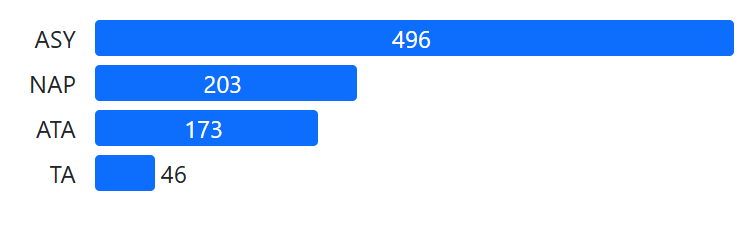


RestingECG:

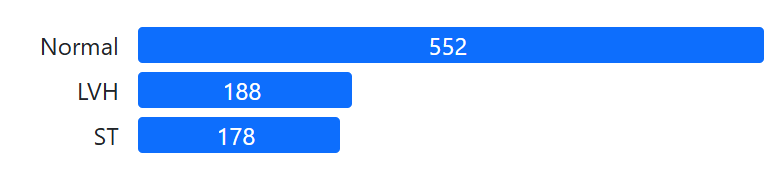

<br>
<br>
<br>
<br>

---

## Overlapping, noise, and correlation/associations

<br>
<br>

##### <b> <u>Step 3a</u>: Major trends</b> 

<i>
After inspecting the trends between your target variable and its features -- Are you noticing anything interesting?
<br>

 Any surprising positive or negative trends?
 
  Any evidence of noise (jittering)?
  
Are your interesting columns linear or non-linear?

Is there anything that 'breaks the rules' of the trend?
 
Please provide visuals of which major trends you found interesting and worthy mentioning.

Hypothesize and, if necessary, research online why this irregular trend occurs.

Also, provide which tool(s) you have used to inspect this aspect of your dataset.

<br>

<u><b>Hint:</b></u> regression plots/scatterplot/pairplot, correlations/phik-matrix/associations, feature importance tools ...

</i>

#### Age vs MaxHR (scatter plot)
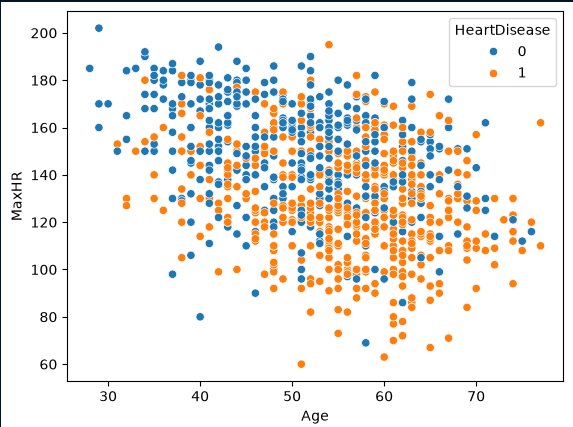

MaxHR goes down as Age goes up, a negative trend. This is expected, since the maximum heart rate drops with age. 

#### Age vs MaxHR (regression lines)
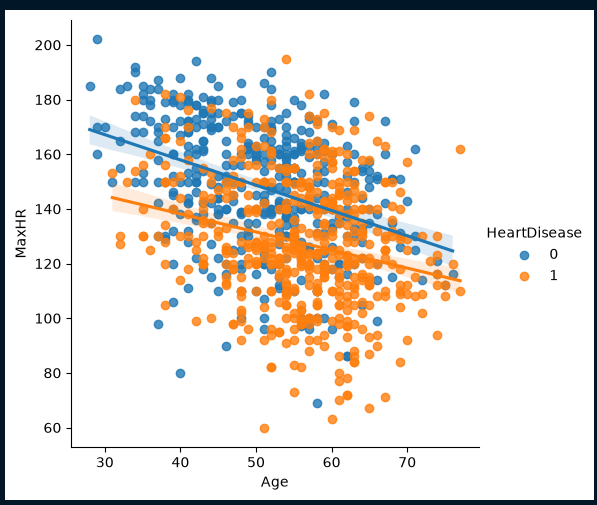

The points are spread widely around the lines (noise), so Age and MaxHR together do not separate the classes cleanly.

#### MaxHR and Oldpeak against the target
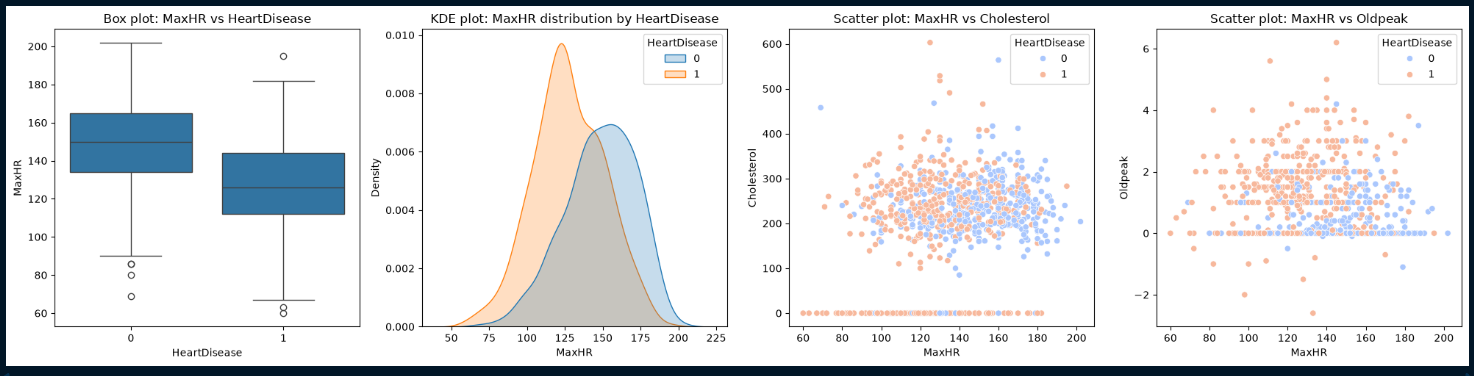

Lower MaxHR goes with heart disease. The curves are shifted but overlap in the middle

#### Oldpeak by ST_Slope
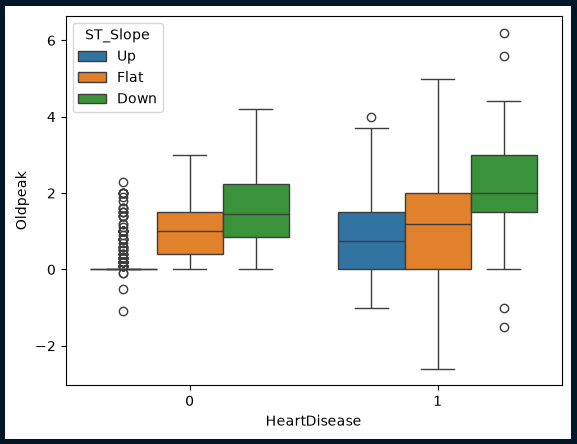

Oldpeak rises from Up to Flat to Down, and is higher in class 1 for the same slope. This is a positive, non-linear trend, since most values are 0 and only the higher values separate the classes.

#### ChestPainType and ST_Slope by HeartDisease (counts)
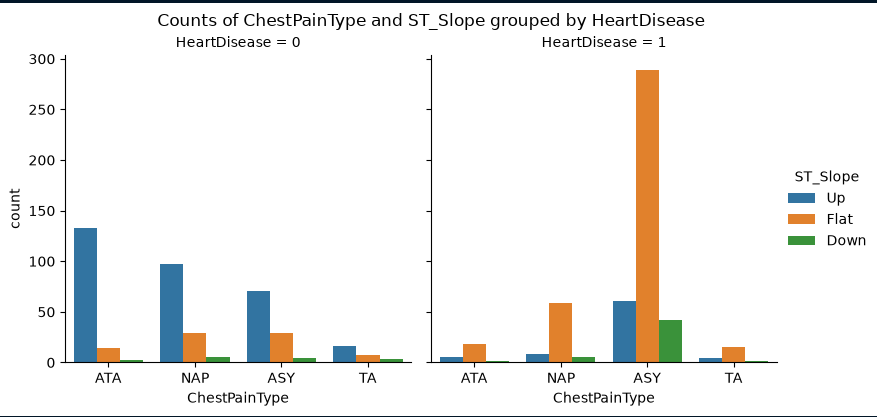

In class 1, ASY with a Flat slope is by far the biggest group. In class 0, most patients have an Up slope

#### Mean target by ChestPainType and ST_Slope (heatmap)
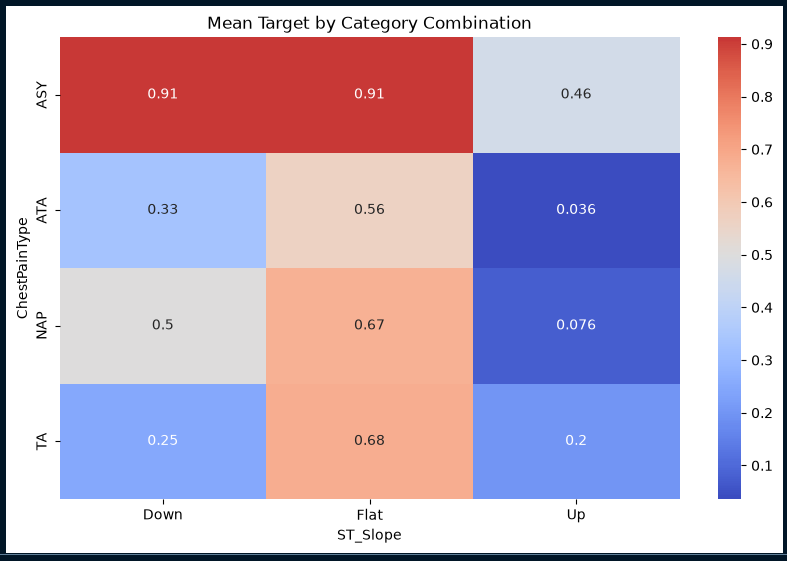

This seem to be the strongest pattern in the data. Patients with ASY chest pain and a Down or Flat slope almost always have heart disease (91%). Patients with ATA or NAP chest pain and an Up slope almost never do (4% to 8%).An Up slope lowers the risk for every chest pain type. Even for ASY, it drops from 91% to 46%.

#### Target distribution by combination (stacked bars)

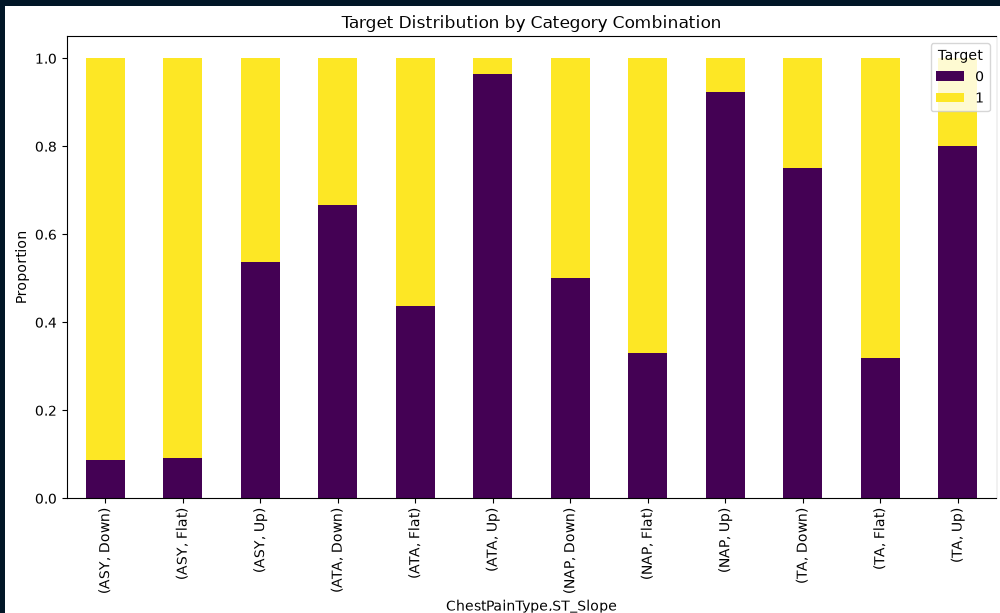

The same trend as in the heatmap. Bars close to 50/50, like (ASY, Up) and (NAP, Down), are can be the classes overlap.

#### Cholesterol vs HeartDisease
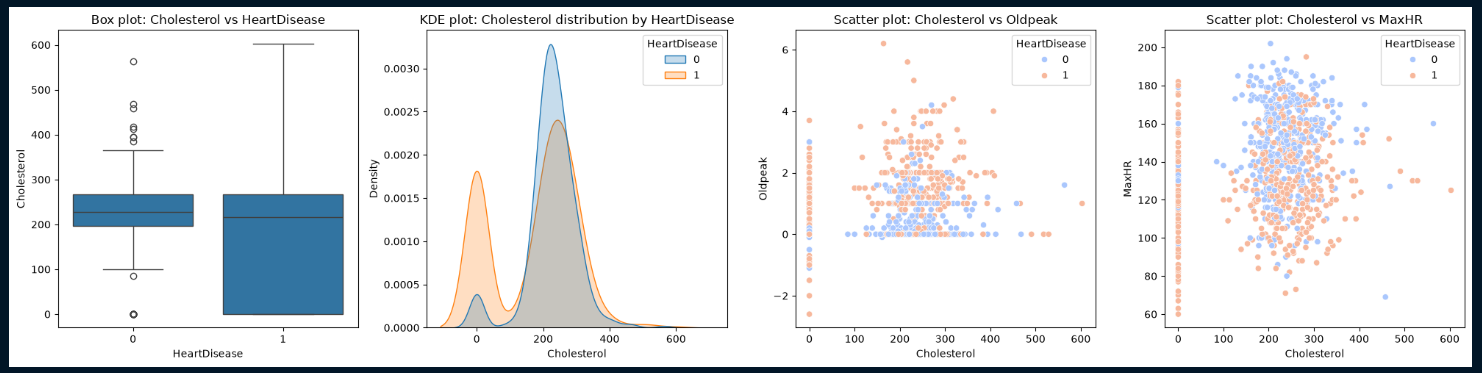

Cholesterol has a negative link with heart disease, which makes no medical sense. The plots show why: there is a second peak at 0 in the KDE, and the zeros are mostly in class 1. These zeros are not real values but missing ones.The zeros can be the patients whose cholesterol was never measured. 

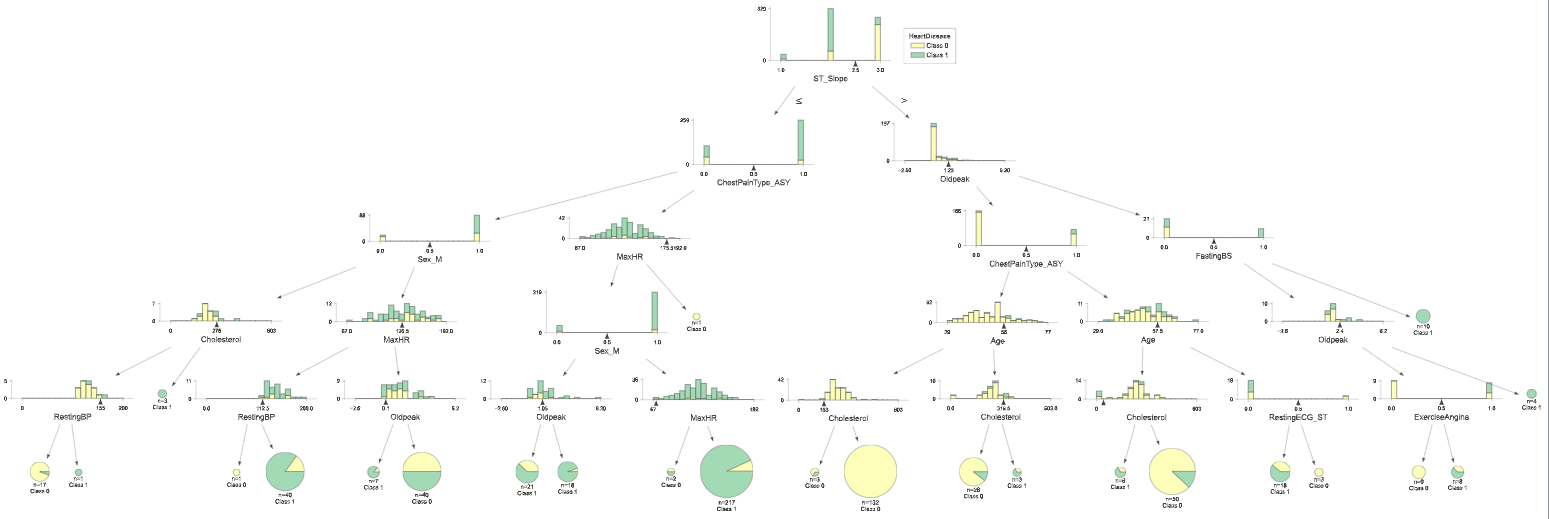
Decision tree implies ST_Slope, ChestPainType (ASY), Oldpeak and MaxHR as the biggest factors in this data. ST_Slope is the root split, with ChestPainType_ASY and Oldpeak right below it. Sex, Age, Cholesterol, RestingBP, FastingBS, RestingECG and ExerciseAngina appear only lower down and affect few patients.

<br>
<br>

##### <b> <u>Step 3b</u>: Overlapping Data</b> 

<i>
Does any overlapping exist between the features and your target variable?
<br>

Do you expect this to be an issue if you were to train a model with this data?

Justify your answer and, if reasonably possible, provide visuals.

Also, provide which tool(s) you have used to inspect this aspect of your dataset.

<br>

<u><b>Hint:</b></u> seaborn box-/scatterplots
</i>

#### Cholesterol vs HeartDisease
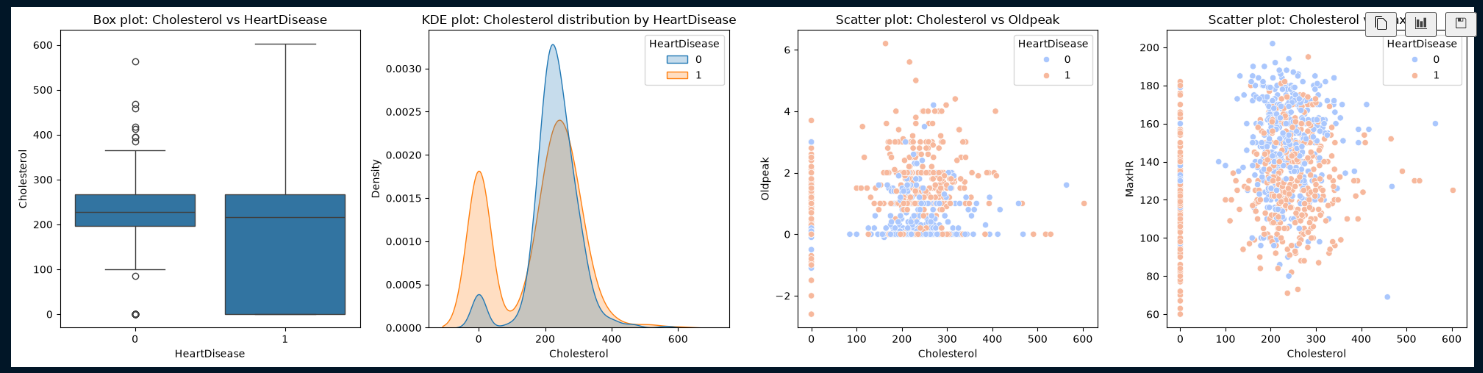
The KDE plot shows a second peak at 0, much larger for HeartDisease = 1.Apart from the zeros, both classes overlap heavily around 200 to 300, so Cholesterol alone separates them poorly. In the scatter plots, the zeros form a vertical line at 0, and the colors are mixed everywhere else with no clear boundary.



#### Oldpeak vs HeartDisease
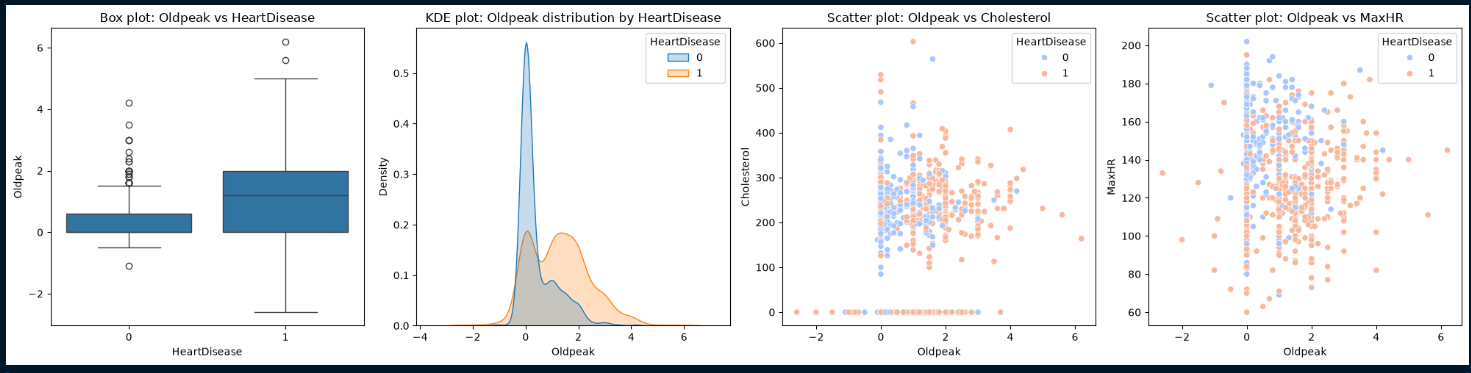

Class 0 is mostly around 0. Class 1 is more spread out and has higher values (median about 1.2).The KDE curves are shifted apart, so Oldpeak is a useful feature, but they still overlap between 0 and 2. In the scatter plots, class 1 sits more to the right, but the colors are still mixed. The few negative values are mostly in class 1.

#### MaxHR vs HeartDisease
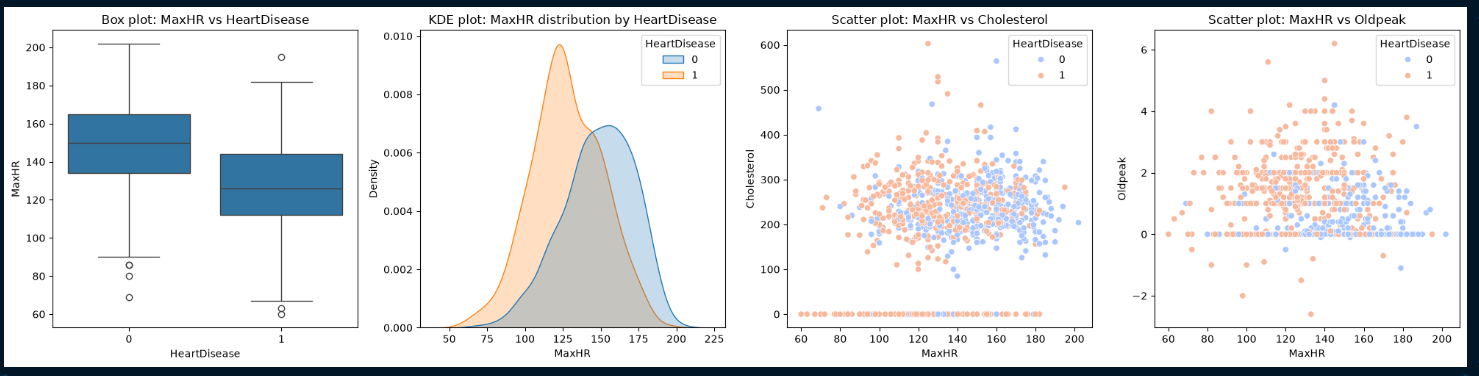
This is the clearest difference of the three. Class 1 has a lower MaxHR (median about 125, against about 150 for class 0).The KDE curves are shifted apart, but they still overlap a lot in the middle (about 110 to 150).In the scatter plots, class 1 tends to have a lower MaxHR and a higher Oldpeak, but the colors are still mixed with no clear line between them

#### Box Plots - Oldpeak by Sex
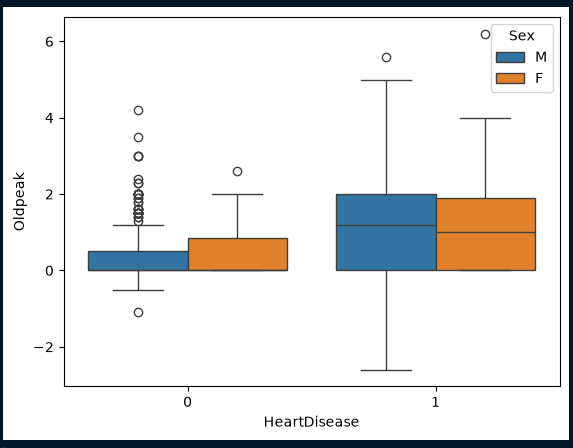

Both types show the same pattern (higher Oldpeak in class 1). Males have more outliers in class 0, partly because there are far more males. Sex does not change the overlap much.

#### Box plots - Oldpeak by ST_Slope
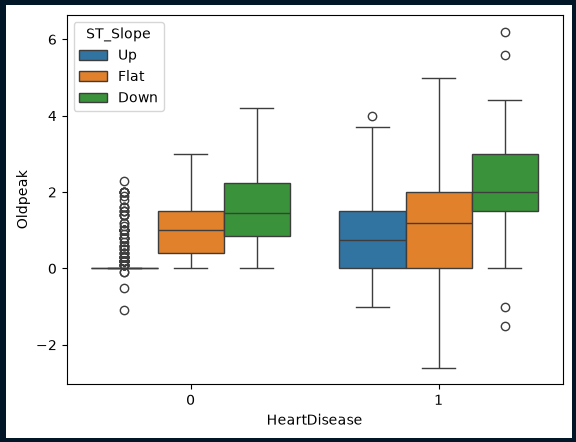

The groups are clearly different: Up is near 0, Flat is in the middle, Down is highest. This shows that Oldpeak and ST_Slope overlap (as in the correlation matrix, 0.50). Within the same slope, the classes still overlap.

#### Box plots: MaxHR by ChestPainType
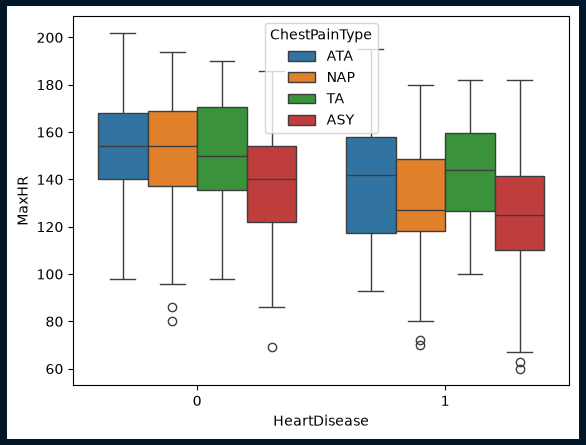

In class 1, ASY has the lowest MaxHR. The other types are similar to each other.The boxes overlap a lot, so ChestPainType explains only part of the MaxHR difference.

#### Box plots - Cholesterol by ExerciseAngina
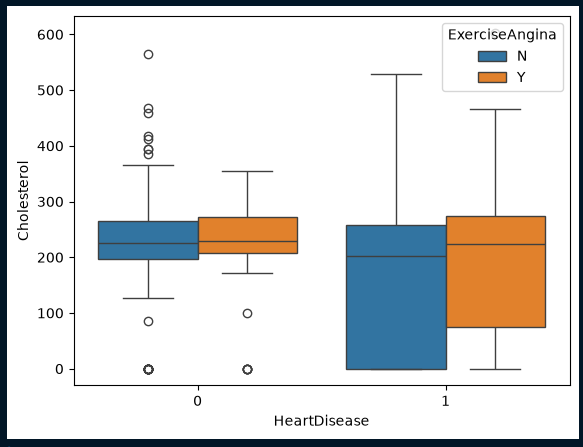

The class 1 boxes extend down to 0, which comes from the zeros (missing values). The ExerciseAngina groups might look similar to each other once the zeros are ignored, so there is little extra overlap information here

#### Count plot: ChestPainType and ST_Slope by HeartDisease
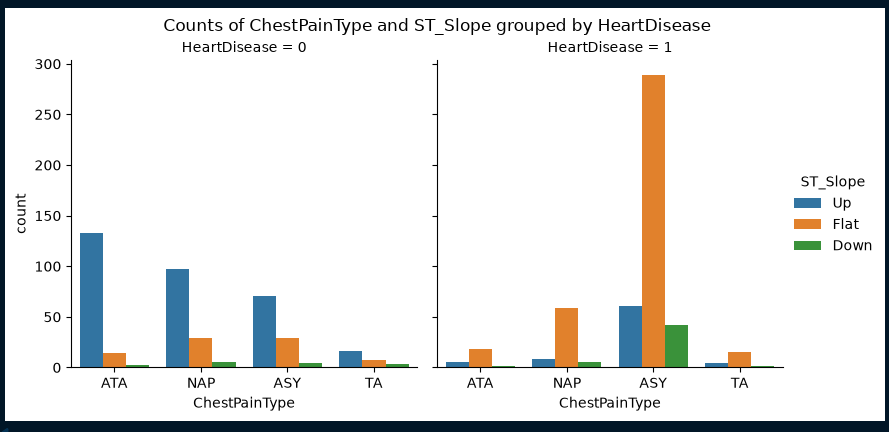

Here it seems these two variables together carry strong information about the target, but they also overlap with each other

#### target distribution by category combination
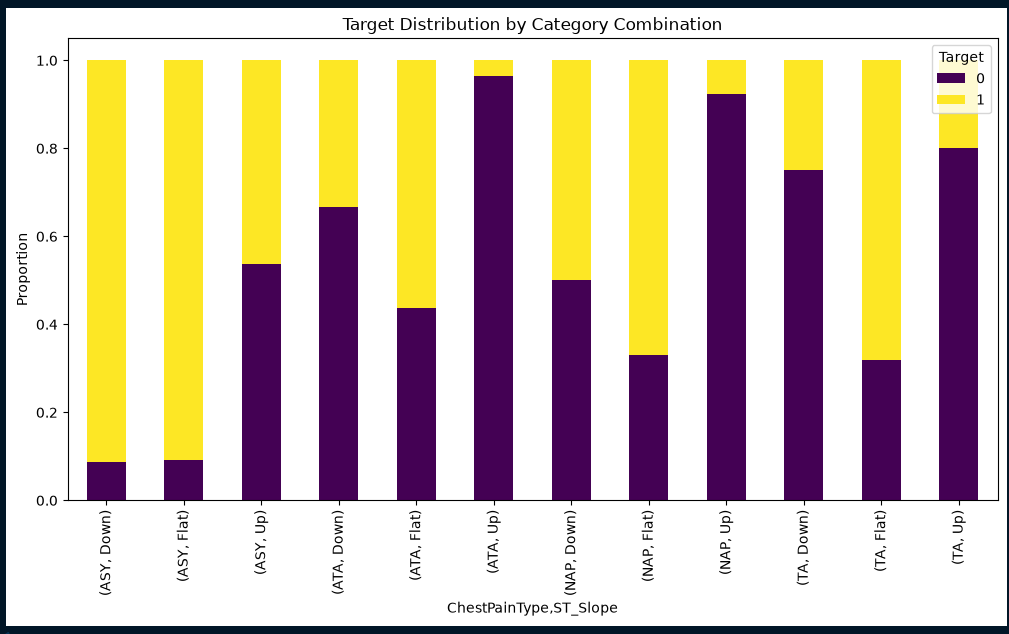

Same as the heatmap. ASY with Down or Flat is almost all class 1, and ATA or NAP with Up is almost all class 0, so these combinations separate the classes well.


#### Cholesterol
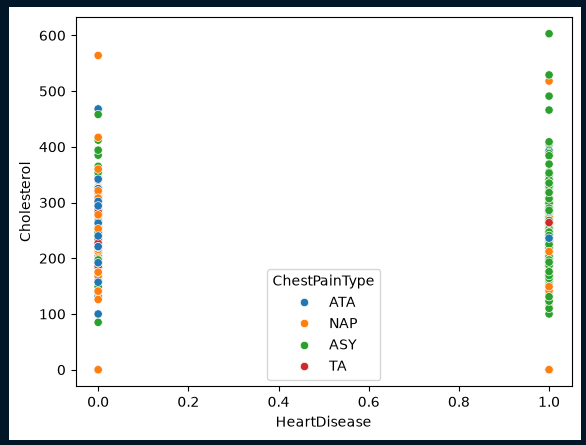

Zeros appear in both classes. Otherwise the classes cover the same range.

#### Oldpeak:

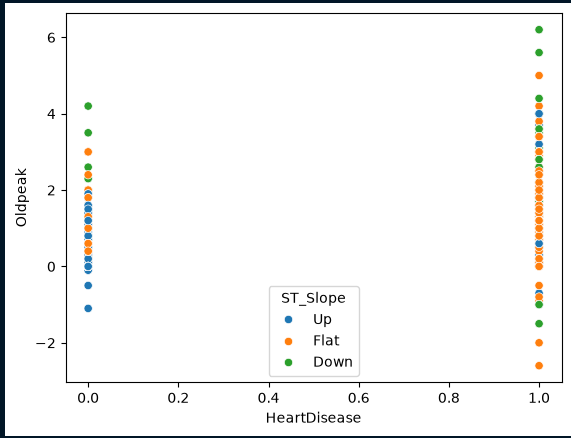

Class 1 reaches higher and lower values

#### MaxHR

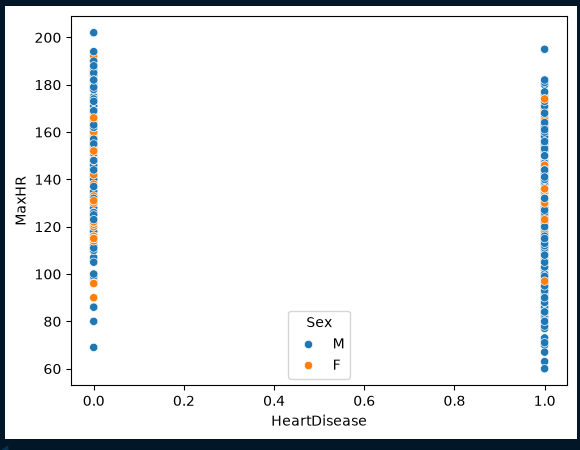
Both classes cover the full range. Few females appear, so Sex adds little here
<br><br>
<br>

##### <b> <u>Step 3c</u>: Outliers & noise</b> 

<i>
Inspect each categorical column for potential outliers and noise. 

<br>

<u>For each column with noise:</u>

In which columns are you detecting noise? Which tool(s) or method(s) did you use to find this?


<u>For each column with outliers:</u>

Are you seeing many outliers in your columns? How extreme (in your opinion) are the outliers? How problematic do you expect this to be if these outliers remained in the dataset? Which tool(s) or method(s) did you use to find this?


<u><b>Hint:</b></u> Isolation Forest, IQR, z-score, Elliptic Envelope, MAD...


</i>

The main problem is the zeros (hidden missing values), which are flagged as outliers, together with a few very high values. Outliers appear in both classes of HeartDisease.
Have to study outliers/noise from other variables too (Oldpeak, RestingBP)

#### Isolation Forest:
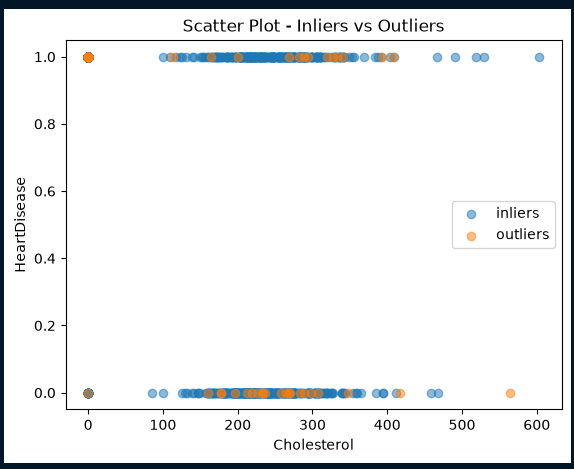

#### Elliptic Envelope
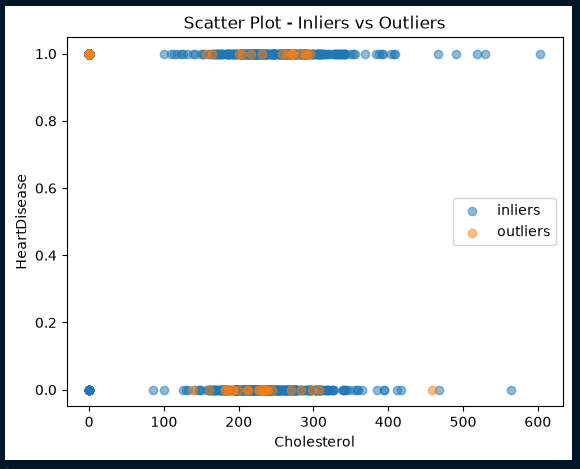

#### MAD

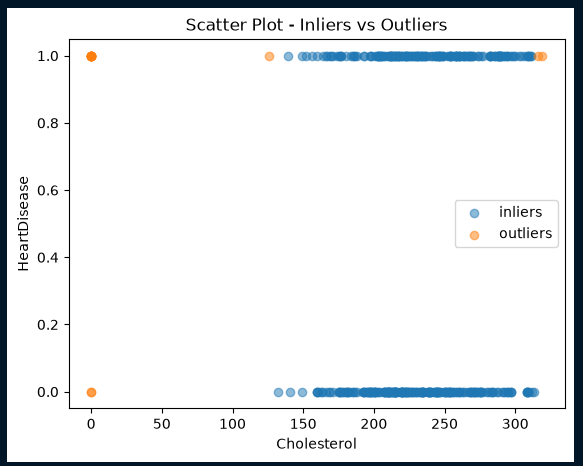



Z-score did not find any outliers
<br>
<br><br>

##### <b> <u>Step 3d</u>: Correlations & associations</b> 

<i>
Inspect the Phi-K and Correlations matrix.

<br>

What kind of linear relationships are you detecting that correlate with your target variable?
 
What kind of non-linear relationships are you detecting that associate with your target variable?

Do you suspect any noise and/or multi-collinearity from these results?

Are there any other interesting things you found?

Justify your answer and provide visuals of the output of both the phi-k and correlation matrix.

<br>

<u><b>Hint:</b></u> Phik/pd.corr + heatmap, or ydata with phik-support, SweetViz -associations, Dython ...


</i>

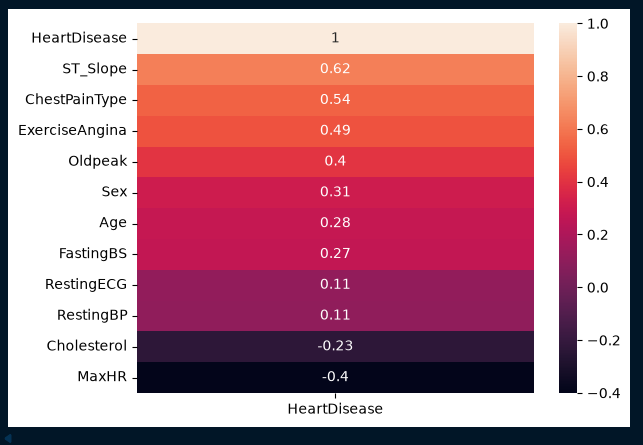

Most variables correlate/associate with the target variable of HeartDisease. ST_Slope, ChestPainType and ExerciseAngina are the strongest. Only RestingECG and RestingBP seem to be disconnected. Cholesterol is negative, which is odd and is caused by the zeros (hidden missing values).

Phik Matrix:

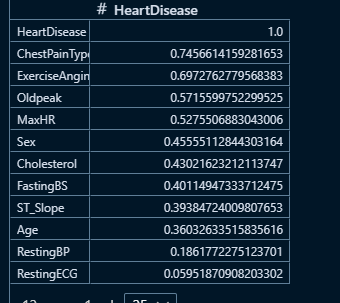

Most variables still associate with the HeartDisease variable. ChestPainType (0.75) and ExerciseAngina (0.70) are the strongest, followed by Oldpeak (0.57) and MaxHR (0.53).
Least effective variables in the Phik-matrix are RestingBP (0.19) and RestingECG (0.06). These match the Dython analysis above.
<br>
<br>
<br>

##### <b> <u>Step 3e</u>: Feature importances</b> 

<i>
Which features seem to be the most important to your target variable?

<br>

How did you come to this conclusion? 
 
Should any of the variables be removed/dropped, or do they need further processing?

<br>

<u><b>Hint:</b></u> Correlation + PhiK matrices, SelectKBest, Fisher Score, RFE ...

</i>

SelectKBest:

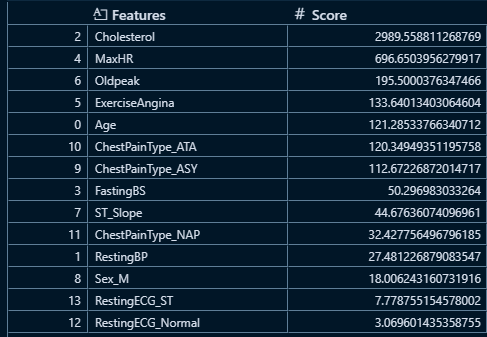

It seems Cholesterol and MaxHR are the most important here, followed by Oldpeak. ExerciseAngina, Age and ChestPainType (ATA and ASY) have medium importance. Other variables have varying degrees of importance. RestingECG (Normal and ST), Sex_M and RestingBP aren’t very effective here. This matches the correlation and Phik results, where RestingECG and RestingBP were the weakest.


Fisher score:

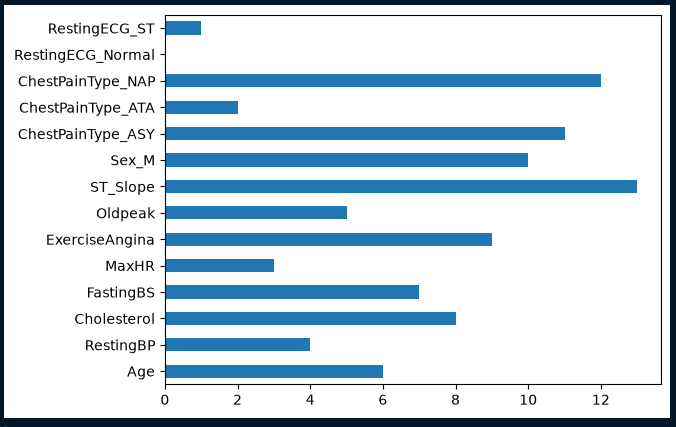

Contradicting results here. ST_Slope is the most important, followed by ChestPainType (NAP and ASY), Sex_M and ExerciseAngina. Most variables show some importance. MaxHR and ChestPainType_ATA rank surprisingly low here, although they were strong in the correlation results. RestingECG (Normal and ST) has almost no impact.

RFE:

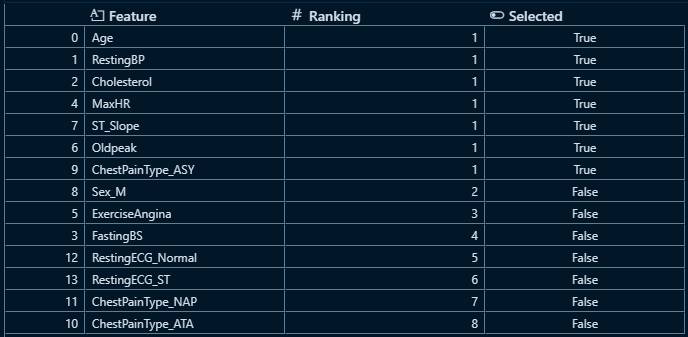

The 7 selected variables are Age, RestingBP, Cholesterol, MaxHR, ST_Slope, Oldpeak and ChestPainType_ASY. The binary and one-hot variables (ChestPainType_ATA and NAP, RestingECG, FastingBS) seem to be least effective here, and Sex_M and ExerciseAngina just miss the cut.

<br>
<br><br>

##### <b> <u>Step 3f</u>: Other potential problems or issues in the dataset? </b>

<i>
If you found anything else that is worth mentioning, and it isn’t found in the previous checklists, you can also elaborate on these for extra points.

<br>

This usually involves limitations in the datasets, weird behavior (e.g. doesn’t make sense from the common sense point of view) or something similar.



</i>

This dataset is fairly small (918 rows) and seems to combine data from several sources, which probably explains the inconsistent recording (the Cholesterol zeros). The data is also unbalanced: about 79% of the patients are male (725 against 193), and ChestPainType_TA has only 46 rows. This can make the model less reliable for women and for the rarer groups

There are also some things that don’t make sense from a common-sense point of view:

<ul>
<li> Patients with ASY (asymptomatic, so no symptoms) chest pain have the highest rate of heart disease. </li>
<li> Cholesterol correlates negatively with heart disease, caused by the zeros. </li>


---

### Summary of findings


<i> Please summarize all of the major findings and issues here briefly. A paragraph or two is fine. Lists are also OK.

</i>


The dataset has 918 rows with no missing values and no duplicates. It still has hidden problems: 172 Cholesterol zeros that could be missing values, and one impossible RestingBP value of 0. The target is only slightly imbalanced (55% heart disease, 45% not), but Sex (79% male) and ChestPainType (only 46 TA rows) are clearly imbalanced. Oldpeak is heavily right-skewed with many zeros, which are valid. Cholesterol has a negative correlation with the target which comes from the same zeros. No categorical column has high cardinality.

The classes overlap in the numeric features (Cholesterol, Oldpeak, MaxHR), so no single numeric feature separates them cleanly. Combinations of ChestPainType and ST_Slope separate them much better.

<ul>
<li>Most important variables: ST_Slope, ChestPainType and ExerciseAngina, followed by Oldpeak and MaxHR.</li>
<li>Least effective variables: RestingECG and RestingBP.</li>
<li>Methods that disagree: SelectKBest, Fisher score and RFE rank some variables differently because they measure different things. </li>

---

##  Advanced tasks (optional, but extra points)

<br>
<br>

##### <b> <u>Step 4a</u>: Under-representation of combinatory categories</b> 

<i>
Are there any combinations of values which are exceptionally rare?

<br>

Example: A client for a bank might have a 18 year old customer with a 23 million Euro outstanding balance. 

Why are they rare? Do you expect these to be problematic? Could they be removed with minor repercussions?

<u><b>Hint:</b></u> Apriori

</i>

<br>
<br><br>

##### <b> <u>Step 4b</u>: Feature creation & derived features</b>

<i>
Can you combine features using operations (+, -, /, *) to make them more useful?

<br>

 Which features would you combine, how, and why?

Example: Credit lenders & debt / income ratio.
Example: Measurable speed – Km / hour

<br>

<u><b>Hint:</u></b> Sometimes, there just isn’t a clear combination of features that makes sense to add to your dataset. However, this problem is mitigated by other tools later in the course.


</i>

<br>
<br><br>

##### <b> <u>Step 4c</u>: Trends between features</b> 

<i>

What can you find when looking at the trends between the features of your dataset?
<br>

Are you noticing some interesting connections and trends?

Could there be some hidden value behind certain features that a machine learning model might find hard to see?
 
<br>

<u><b>Example:</b></u> House condition --> House quality -->  Price

<br>

Does any redundancy exist between these features?

Do you believe this trend would make a negative impact on your model?

Please show visuals of the most interesting feature-feature trends (scatterplot, regplot)

Which tool(s) did you use to inspect this?

<br>

<u><b>Hint:</b></u> You will find these especially (but are not limited to) in time-series data. Seaborn.regplots with hue are really useful here

<br>
<br><br>

</i>

##### <b><u>Step 4d</u>: Conventional EDA vs. tools </b>

<i>
Verify that the results in the tools are correct by using the conventional data-analytics skillset in Python. 

<br>

Use manual EDA (Exploratory Data Analysis), or in other words, <u>all the previous skills you have learnt in earlier data analytics studies.</u>

Verify with pandas features and seaborn visualizations and make sure the analysis of these tools are actually correct.

Are there any contradictions between the the new tools you've used and your own analysis?

<br><br>


##### <b> <u>Step 4e</u>: Non-linear connections / polynomial trends </b>

<i>
One of the features the evaluation tools have difficulties with is visualizing any non-linear connections in a dataset.

<br>

Seaborn, and its regression plot function, has a feature that supports polynomial regression as well.

For the most complicated pairs of variables, try using polynomial regression plots in your dataset and analyze the amount of noise, outliers and complexity your data might have.

</i>